In [ ]:
import os
import utils


import utils
import pickle
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision import datasets

# Parametri

In [ ]:
os.makedirs("histories", exist_ok=True)

EPOCHS = 10
BATCH_SIZE = 256
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.DEVICE('cpu')

print(f"DEVICE: {DEVICE}")

# Dataset

TRAIN SET shape: (50000, 32, 32, 3)
TEST SET shape:  (10000, 32, 32, 3)


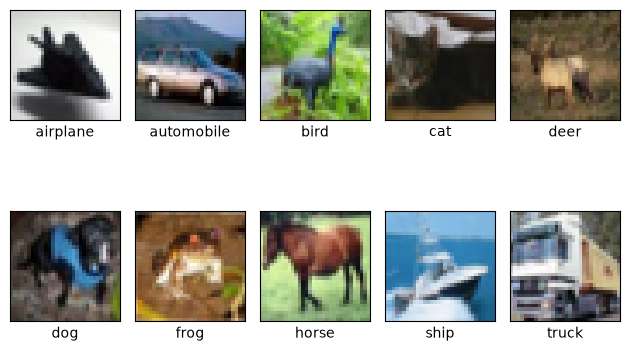

In [4]:
from datasets.datasets import load_CIFAR10
train_dataset, test_dataset, train_loader, test_loader = load_CIFAR10(batch_size=BATCH_SIZE, verbose=False)

print(f"TRAIN SET shape: {train_dataset.data.shape}")
print(f"TEST SET shape:  {test_dataset.data.shape}")

for c in range(len(train_dataset.classes)):
    idx = train_dataset.targets.index(c)   # primo esempio della classe c
    img, label = train_dataset[idx]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.permute(1, 2, 0))
    plt.xlabel(train_dataset.classes[label])
plt.tight_layout()
plt.show()

## Modelli

In [8]:
criterion = nn.CrossEntropyLoss()

#### DNN

In [9]:
model_dense = nn.Sequential(
    nn.Flatten(),
    nn.LazyLinear(100), nn.ReLU(),
    # nn.Linear(3*32*32,100), nn.ReLU(),
    nn.Linear(100, 10)
).to(DEVICE)

optimizer_dense = torch.optim.Adam(model_dense.parameters(), lr=1e-3)
utils.summary(model_dense, (32, 32, 3))

Layer (type)                Output Shape               Param #
0 (Flatten)                 (None, 3072)                     0
1 (Linear)                  (None, 100)                307,300
2 (ReLU)                    (None, 100)                      0
3 (Linear)                  (None, 10)                   1,010
Total params: 308,310
Trainable params: 308,310
Non-trainable params: 0


#### CNN

In [10]:
model_conv = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),
    nn.Flatten(),
    nn.LazyLinear(64), nn.ReLU(),
    nn.Linear(64, 10)
).to(DEVICE)

optimizer_conv = torch.optim.Adam(model_conv.parameters(), lr=1e-3)
utils.summary(model_conv, (3, 32, 32))

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 30, 30)             896
1 (ReLU)                    (None, 32, 30, 30)               0
2 (MaxPool2d)               (None, 32, 15, 15)               0
3 (Conv2d)                  (None, 64, 13, 13)          18,496
4 (ReLU)                    (None, 64, 13, 13)               0
5 (MaxPool2d)               (None, 64, 6, 6)                 0
6 (Conv2d)                  (None, 64, 4, 4)            36,928
7 (ReLU)                    (None, 64, 4, 4)                 0
8 (Flatten)                 (None, 1024)                     0
9 (Linear)                  (None, 64)                  65,600
10 (ReLU)                   (None, 64)                       0
11 (Linear)                 (None, 10)                     650
Total params: 122,570
Trainable params: 122,570
Non-trainable params: 0


# Addestramento

### DNN

  0%|          | 0/10 [00:00<?, ?it/s]

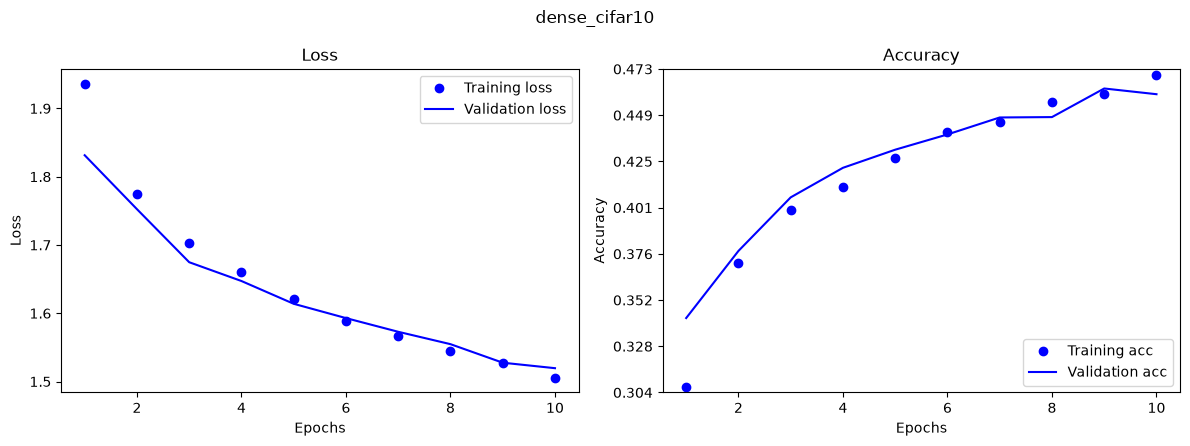

In [11]:
name = "dense_cifar10"

exists = os.path.isfile(f'histories/{name}.hist') and os.path.isfile(f'histories/{name}.pt')
if exists:
    with open(f'histories/{name}.hist','rb') as hist_file:
        history_dict = pickle.load(hist_file)
    model_dense.load_state_dict(torch.load(f'histories/{name}.pt', map_location=DEVICE))
else:
    history_dict = utils.train(model_dense, optimizer_dense, criterion, train_loader, test_loader, epochs=EPOCHS, device=DEVICE)

    with open(f'histories/{name}.hist','wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(model_dense.state_dict(), f'histories/{name}.pt')
    
utils.hist_plot(history_dict, name)


### CNN

  0%|          | 0/10 [00:00<?, ?it/s]

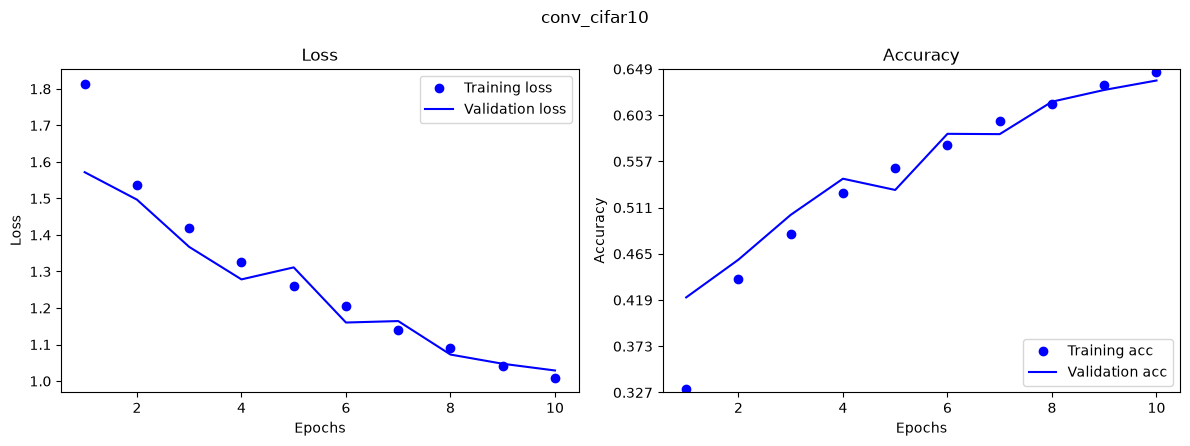

In [12]:
name = "conv_cifar10"

exists = os.path.isfile(f'histories/{name}.hist') and os.path.isfile(f'histories/{name}.pt')
if exists:
    with open(f'histories/{name}.hist','rb') as hist_file:
        history_dict = pickle.load(hist_file)
    model_conv.load_state_dict(torch.load(f'histories/{name}.pt', map_location=DEVICE))
else:
    history_dict = utils.train(model_conv, optimizer_conv, criterion, train_loader, test_loader, epochs=EPOCHS, device=DEVICE)

    with open(f'histories/{name}.hist','wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(model_conv.state_dict(), f'histories/{name}.pt')
utils.hist_plot(history_dict, name)